# Does a world model help decisions?

**Claim status: illustrative state-space analogue.** This lesson fits a small transition model in MountainCar. It does not implement JEPA or reproduce either cited paper.

## Learning outcome

Measure whether a fitted model predicts outcomes under changed actions, then compare its planner with a direct control policy on paired episodes.

## What this lesson uses

- Task: Gymnasium MountainCarContinuous, with a fixed goal position of 0.25.
- Model: a polynomial state-transition regressor fitted on simulator-generated episodes.
- Intervention: actions -1, 0, and 1 from each of 20 held-out states.
- Closed-loop comparison: learned-model MPC versus a direct momentum rule on 20 identical starts.
- No external data, checkpoint, or robot is needed.

## Prerequisites and expected output

Use the project notebook setup in the README. Basic Python and the control terms state, action, and return are enough. This lesson uses the existing NumPy, scikit-learn, and Gymnasium packages; PyTorch is not required.

The notebook reports at least 60 action interventions, prediction and ranking measures, and 20 paired episodes per policy with success, return, elapsed time, model calls, and missing-run status.

The position paper argues that counterfactual action fidelity and closed-loop use need direct evidence. The benchmark survey reports 11 explicit world-model versus direct-policy comparisons among 160 benchmarks. These papers motivate the measurements; the local simulator results do not reproduce their findings.

## Fixed protocol

Training, intervention, and evaluation use separate reset seeds. The transition model fits only training episodes. Each intervention compares all three candidate actions from the same starting state. Success means reaching position 0.25 or beyond with non-negative velocity. The policy comparison uses the same evaluation seeds, goal, 300-step episode limit, and 60-second elapsed-time cap per method.

The direct baseline is the momentum rule from Notebook 10: apply positive force when velocity is non-negative and negative force otherwise. The planner uses CEM over the fitted transition model. It has more internal model calls than the direct policy; the notebook reports actual time and call counts and does not hide this difference.

In [1]:
import itertools
import os
import platform
import time

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display
from sklearn.linear_model import Ridge
from sklearn.preprocessing import PolynomialFeatures

GOAL_POSITION = 0.25
MAX_STEPS = 300
TRAIN_SEEDS = tuple(range(1000, 1020))
INTERVENTION_SEEDS = tuple(range(2000, 2005))
EVALUATION_SEEDS = tuple(range(3000, 3020))
ACTIONS = (-1.0, 0.0, 1.0)
EVALUATION_CAP_SECONDS = 60.0
CEM_HORIZON = 10
CEM_CANDIDATES = 64
CEM_ELITES = 8
CEM_ITERATIONS = 2

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("scikit-learn:", __import__("sklearn").__version__)
print("Gymnasium:", gym.__version__)
print("Platform:", platform.platform())
print("CPU:", platform.processor() or platform.machine())
print("Logical CPUs:", os.cpu_count())
print("Device:", "CPU; no GPU code path used")
print("Training seeds:", TRAIN_SEEDS[0], "through", TRAIN_SEEDS[-1])
print("Intervention seeds:", INTERVENTION_SEEDS[0], "through", INTERVENTION_SEEDS[-1])
print("Evaluation seeds:", EVALUATION_SEEDS[0], "through", EVALUATION_SEEDS[-1])
print("Policy evaluation cap:", EVALUATION_CAP_SECONDS, "seconds per method")

Python: 3.13.14
NumPy: 2.5.4
scikit-learn: 1.9.1
Gymnasium: 0.29.1
Platform: Linux-6.18.54.1-microsoft-standard-WSL2-x86_64-with-glibc2.35
CPU: x86_64
Logical CPUs: 24
Device: CPU; no GPU code path used
Training seeds: 1000 through 1019
Intervention seeds: 2000 through 2004
Evaluation seeds: 3000 through 3019
Policy evaluation cap: 60.0 seconds per method


## Check the simulator transition

The model learns next state from current position, velocity, and action. This helper is used to check the local transition equations against Gymnasium and to apply the fitted model in batches.

In [2]:
MIN_POSITION = -1.2
MAX_POSITION = 0.6
MAX_SPEED = 0.07
POWER = 0.0015
GRAVITY = 0.0025

def true_step(states, actions):
    states = np.asarray(states, dtype=np.float32)
    actions = np.asarray(actions, dtype=np.float32)
    position = states[..., 0]
    velocity = states[..., 1]
    force = np.clip(actions, -1.0, 1.0)
    next_velocity = np.clip(
        velocity + force * POWER - GRAVITY * np.cos(3.0 * position),
        -MAX_SPEED,
        MAX_SPEED,
    )
    next_position = np.clip(position + next_velocity, MIN_POSITION, MAX_POSITION)
    next_velocity = np.where(
        (next_position == MIN_POSITION) & (next_velocity < 0.0),
        0.0,
        next_velocity,
    )
    return np.stack((next_position, next_velocity), axis=-1).astype(np.float32)

env = gym.make("MountainCarContinuous-v0", max_episode_steps=MAX_STEPS)
env.unwrapped.goal_position = GOAL_POSITION
transition_cases = [
    ([-0.55, 0.0], 1.0),
    ([-0.50, 0.04], -0.5),
    ([-1.20, -0.03], -1.0),
    ([0.24, 0.02], 1.0),
]
transition_errors = []
for state, action in transition_cases:
    env.reset(seed=17)
    env.unwrapped.state = np.asarray(state, dtype=np.float32)
    observed, _, _, _, _ = env.step(np.asarray([action], dtype=np.float32))
    predicted = true_step(np.asarray(state, dtype=np.float32), action)
    transition_errors.append(float(np.max(np.abs(observed - predicted))))
max_transition_error = max(transition_errors)
print("Maximum simulator-transition error on fixed cases:", max_transition_error)
assert max_transition_error < 1e-7

Maximum simulator-transition error on fixed cases: 1.862645149230957e-09


## Collect training transitions and fit the model

The training data comes from random actions in the simulator. Evaluation and intervention seeds are held out. The regression model is deterministic, so model-training seed variation does not apply.

In [3]:
train_inputs = []
train_targets = []
training_episode_sizes = []

for seed in TRAIN_SEEDS:
    observation, _ = env.reset(seed=seed)
    rng = np.random.default_rng(seed + 50000)
    episode_size = 0
    for _ in range(MAX_STEPS):
        state = observation.copy()
        action = float(rng.uniform(-1.0, 1.0))
        next_observation, _, terminated, truncated, _ = env.step(
            np.asarray([action], dtype=np.float32)
        )
        train_inputs.append([float(state[0]), float(state[1]), action])
        train_targets.append(next_observation.astype(np.float64))
        observation = next_observation
        episode_size += 1
        if terminated or truncated:
            break
    training_episode_sizes.append(episode_size)

train_inputs = np.asarray(train_inputs, dtype=np.float64)
train_targets = np.asarray(train_targets, dtype=np.float64)
poly = PolynomialFeatures(degree=3, include_bias=True)
train_features = poly.fit_transform(train_inputs)
regressor = Ridge(alpha=1e-6, fit_intercept=False)
regressor.fit(train_features, train_targets)
model_powers = poly.powers_.copy()
model_weights = regressor.coef_.T.copy()

def polynomial_features(inputs):
    inputs = np.asarray(inputs, dtype=np.float64)
    return np.prod(
        np.power(inputs[:, None, :], model_powers[None, :, :]),
        axis=2,
    )

def learned_step(states, actions):
    states = np.asarray(states, dtype=np.float64)
    actions = np.asarray(actions, dtype=np.float64)
    inputs = np.column_stack((states, actions.reshape(-1)))
    prediction = polynomial_features(inputs) @ model_weights
    position = np.clip(prediction[:, 0], MIN_POSITION, MAX_POSITION)
    velocity = np.clip(prediction[:, 1], -MAX_SPEED, MAX_SPEED)
    velocity = np.where((position == MIN_POSITION) & (velocity < 0.0), 0.0, velocity)
    return np.column_stack((position, velocity))

print("Training transitions:", len(train_inputs))
print("Training episodes:", len(training_episode_sizes))
print("Transitions per episode:", training_episode_sizes)
print("Polynomial features:", len(model_powers))

Training transitions: 6000
Training episodes: 20
Transitions per episode: [300, 300, 300, 300, 300, 300, 300, 300, 300, 300, 300, 300, 300, 300, 300, 300, 300, 300, 300, 300]
Polynomial features: 20


## Measure action interventions

For each held-out state, the notebook applies all three candidate actions from the same state in the simulator and in the fitted model. Ranking agreement uses every pair whose predicted and observed utilities are both non-tied. It reports how many pairs were excluded.

Intervention outcomes: 60
Held-out states: 20
Actions per state: 3
Mean absolute position error: 2.2851881428254118e-07
Mean absolute velocity error: 2.7161673733929357e-07
Pairwise utility-ranking agreement: 1.0
Non-tied pairs: 60
Pairs excluded because predicted or observed utility tied: 0


State,Action,Observed x,Observed v,Predicted x,Predicted v,x error,v error,Observed utility,Predicted utility
0,-1.000000,-0.486762,-0.001789,-0.486762,-0.001789,0.000000,0.000000,-0.542818,-0.542818
0,0.000000,-0.485262,-0.000289,-0.485262,-0.000289,0.000000,0.000000,-0.540610,-0.540610
0,1.000000,-0.483762,0.001211,-0.483762,0.001211,0.000000,0.000000,-0.538406,-0.538406
1,-1.000000,-0.574338,0.006790,-0.574338,0.006790,0.000000,0.000000,-0.679535,-0.679535
1,0.000000,-0.572838,0.008290,-0.572838,0.008290,0.000000,0.000000,-0.677065,-0.677065
1,1.000000,-0.571338,0.009790,-0.571338,0.009790,0.000000,0.000000,-0.674600,-0.674600
2,-1.000000,-0.503745,-0.006211,-0.503745,-0.006211,-0.000000,-0.000000,-0.568134,-0.568134
2,0.000000,-0.502245,-0.004711,-0.502245,-0.004711,0.000000,-0.000000,-0.565874,-0.565874
2,1.000000,-0.500745,-0.003211,-0.500745,-0.003211,-0.000000,-0.000000,-0.563619,-0.563619
3,-1.000000,-0.512694,0.001644,-0.512694,0.001644,0.000000,0.000000,-0.581703,-0.581702


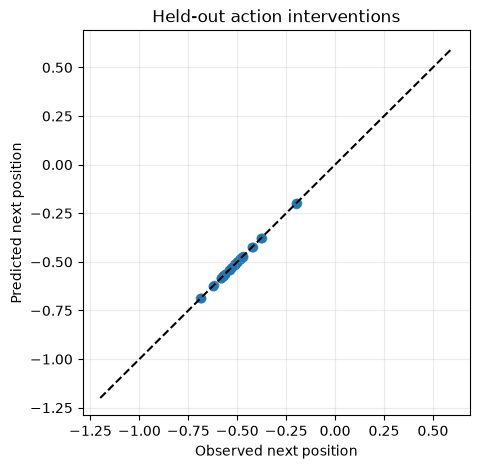

In [4]:
heldout_states = []
for seed in INTERVENTION_SEEDS:
    observation, _ = env.reset(seed=seed)
    rng = np.random.default_rng(seed + 70000)
    path_states = []
    for _ in range(MAX_STEPS):
        path_states.append(observation.copy())
        action = float(rng.uniform(-1.0, 1.0))
        observation, _, terminated, truncated, _ = env.step(
            np.asarray([action], dtype=np.float32)
        )
        if terminated or truncated:
            break
    chosen = np.linspace(0, len(path_states) - 1, 4, dtype=int)
    heldout_states.extend(path_states[index].copy() for index in chosen)

heldout_states = np.asarray(heldout_states[:20], dtype=np.float32)
assert heldout_states.shape == (20, 2)

def utility(states):
    states = np.asarray(states)
    return -((states[..., 0] - GOAL_POSITION) ** 2 + 0.05 * states[..., 1] ** 2)

intervention_records = []
pairwise_correct = 0
pairwise_total = 0
excluded_ties = 0
for state_index, state in enumerate(heldout_states):
    predicted_outcomes = learned_step(
        np.repeat(state[None, :], len(ACTIONS), axis=0),
        np.asarray(ACTIONS),
    )
    observed_outcomes = []
    for action in ACTIONS:
        env.reset(seed=0)
        env.unwrapped.state = state.copy()
        next_observation, _, _, _, _ = env.step(
            np.asarray([action], dtype=np.float32)
        )
        observed_outcomes.append(next_observation.copy())
    observed_outcomes = np.asarray(observed_outcomes)
    predicted_utilities = utility(predicted_outcomes)
    observed_utilities = utility(observed_outcomes)

    for action_index, action in enumerate(ACTIONS):
        error = predicted_outcomes[action_index] - observed_outcomes[action_index]
        intervention_records.append({
            "state_index": state_index,
            "action": action,
            "observed_position": float(observed_outcomes[action_index, 0]),
            "observed_velocity": float(observed_outcomes[action_index, 1]),
            "predicted_position": float(predicted_outcomes[action_index, 0]),
            "predicted_velocity": float(predicted_outcomes[action_index, 1]),
            "position_error": float(error[0]),
            "velocity_error": float(error[1]),
            "observed_utility": float(observed_utilities[action_index]),
            "predicted_utility": float(predicted_utilities[action_index]),
        })

    for left, right in itertools.combinations(range(len(ACTIONS)), 2):
        observed_difference = observed_utilities[left] - observed_utilities[right]
        predicted_difference = predicted_utilities[left] - predicted_utilities[right]
        if abs(observed_difference) <= 1e-12 or abs(predicted_difference) <= 1e-12:
            excluded_ties += 1
        else:
            pairwise_total += 1
            pairwise_correct += int(np.sign(observed_difference) == np.sign(predicted_difference))

intervention_mae_position = float(np.mean([
    abs(row["position_error"]) for row in intervention_records
]))
intervention_mae_velocity = float(np.mean([
    abs(row["velocity_error"]) for row in intervention_records
]))
ranking_agreement = (
    pairwise_correct / pairwise_total if pairwise_total else float("nan")
)

print("Intervention outcomes:", len(intervention_records))
print("Held-out states:", len(heldout_states))
print("Actions per state:", len(ACTIONS))
print("Mean absolute position error:", intervention_mae_position)
print("Mean absolute velocity error:", intervention_mae_velocity)
print("Pairwise utility-ranking agreement:", ranking_agreement)
print("Non-tied pairs:", pairwise_total)
print("Pairs excluded because predicted or observed utility tied:", excluded_ties)

rows = []
for row in intervention_records:
    rows.append(
        "<tr>" + "".join(
            f"<td>{row[key]:.6f}</td>" if isinstance(row[key], float)
            else f"<td>{row[key]}</td>"
            for key in [
                "state_index", "action", "observed_position", "observed_velocity",
                "predicted_position", "predicted_velocity", "position_error",
                "velocity_error", "observed_utility", "predicted_utility",
            ]
        ) + "</tr>"
    )
headers = [
    "State", "Action", "Observed x", "Observed v", "Predicted x",
    "Predicted v", "x error", "v error", "Observed utility", "Predicted utility",
]
table = "<table><thead><tr>" + "".join(f"<th>{item}</th>" for item in headers)
table += "</tr></thead><tbody>" + "".join(rows) + "</tbody></table>"
display(HTML(table))

fig, axis = plt.subplots(figsize=(5, 5))
axis.scatter(
    [row["observed_position"] for row in intervention_records],
    [row["predicted_position"] for row in intervention_records],
    alpha=0.7,
)
bounds = [MIN_POSITION, MAX_POSITION]
axis.plot(bounds, bounds, linestyle="--", color="black")
axis.set(xlabel="Observed next position", ylabel="Predicted next position",
         title="Held-out action interventions")
axis.grid(alpha=0.25)
plt.show()

## Compare closed-loop outcomes

The planner sees the fitted model and replans after each observed action. The direct policy sees the current state and applies the momentum rule. Both use the same evaluation seeds, success rule, episode limit, and 60-second elapsed-time cap. The cap is a maximum; actual time and model calls are reported for each method.

In [5]:
def plan_with_cem(start_state, rng):
    mean = np.zeros(CEM_HORIZON, dtype=np.float64)
    standard_deviation = np.full(CEM_HORIZON, 0.8, dtype=np.float64)
    model_calls = 0
    for _ in range(CEM_ITERATIONS):
        candidates = rng.normal(
            mean,
            standard_deviation,
            size=(CEM_CANDIDATES, CEM_HORIZON),
        )
        candidates = np.clip(candidates, -1.0, 1.0)
        states = np.repeat(np.asarray(start_state, dtype=np.float64)[None, :],
                           CEM_CANDIDATES, axis=0)
        costs = np.zeros(CEM_CANDIDATES, dtype=np.float64)
        for step in range(CEM_HORIZON):
            actions = candidates[:, step]
            states = learned_step(states, actions)
            model_calls += CEM_CANDIDATES
            costs += (
                (GOAL_POSITION - states[:, 0]) ** 2
                + 0.05 * states[:, 1] ** 2
                + 0.001 * actions ** 2
            )
        elite_indices = np.argsort(costs)[:CEM_ELITES]
        elites = candidates[elite_indices]
        mean = elites.mean(axis=0)
        standard_deviation = np.maximum(elites.std(axis=0), 0.05)
    return float(np.clip(mean[0], -1.0, 1.0)), model_calls

def momentum_policy(state):
    return 1.0 if state[1] >= 0.0 else -1.0

def run_episode(method, seed):
    observation, _ = env.reset(seed=seed)
    rng = np.random.default_rng(seed + 90000)
    episode_return = 0.0
    model_calls = 0
    success = False
    steps = 0
    for step in range(MAX_STEPS):
        state = observation.copy()
        if method == "learned_model_mpc":
            action, calls = plan_with_cem(state, rng)
            model_calls += calls
        else:
            action = momentum_policy(state)
        observation, reward, terminated, truncated, _ = env.step(
            np.asarray([action], dtype=np.float32)
        )
        episode_return += float(reward)
        steps = step + 1
        success = bool(
            observation[0] >= GOAL_POSITION and observation[1] >= 0.0
        )
        if terminated or truncated:
            break
    return {
        "method": method,
        "seed": seed,
        "status": "complete",
        "success": success,
        "return": episode_return,
        "steps": steps,
        "model_calls": model_calls,
    }

evaluation_records = []
method_runtime = {}
method_complete = {}
for method in ("learned_model_mpc", "direct_momentum"):
    started = time.perf_counter()
    records = []
    complete = True
    for seed in EVALUATION_SEEDS:
        if time.perf_counter() - started >= EVALUATION_CAP_SECONDS:
            complete = False
            records.extend({
                "method": method,
                "seed": missing_seed,
                "status": "missing_budget",
                "success": None,
                "return": None,
                "steps": None,
                "model_calls": 0,
            } for missing_seed in EVALUATION_SEEDS if missing_seed >= seed)
            break
        records.append(run_episode(method, seed))
    elapsed = time.perf_counter() - started
    if elapsed > EVALUATION_CAP_SECONDS:
        complete = False
    for row in records:
        row["elapsed_seconds"] = elapsed
    evaluation_records.extend(records)
    method_runtime[method] = elapsed
    method_complete[method] = complete

print("Method evaluation times:", method_runtime)
print("Methods within the shared elapsed-time cap:", method_complete)
print("Completed evaluation episodes:",
      sum(row["status"] == "complete" for row in evaluation_records))

Method evaluation times: {'learned_model_mpc': 12.746790320998116, 'direct_momentum': 0.007146505005948711}
Methods within the shared elapsed-time cap: {'learned_model_mpc': True, 'direct_momentum': True}
Completed evaluation episodes: 40


In [6]:
def wilson_interval(successes, total, z=1.959963984540054):
    if total == 0:
        return float("nan"), float("nan")
    rate = successes / total
    denominator = 1.0 + z * z / total
    center = (rate + z * z / (2.0 * total)) / denominator
    margin = z * np.sqrt(
        rate * (1.0 - rate) / total + z * z / (4.0 * total * total)
    ) / denominator
    return max(0.0, center - margin), min(1.0, center + margin)

summary_rows = []
for method in ("learned_model_mpc", "direct_momentum"):
    rows = [
        row for row in evaluation_records
        if row["method"] == method and row["status"] == "complete"
    ]
    successes = sum(bool(row["success"]) for row in rows)
    low, high = wilson_interval(successes, len(rows))
    summary_rows.append({
        "method": method,
        "completed": len(rows),
        "successes": successes,
        "success_rate": successes / len(rows) if rows else float("nan"),
        "wilson_low": low,
        "wilson_high": high,
        "mean_return": float(np.mean([row["return"] for row in rows]))
            if rows else float("nan"),
        "mean_steps": float(np.mean([row["steps"] for row in rows]))
            if rows else float("nan"),
        "model_calls": int(sum(row["model_calls"] for row in rows)),
        "elapsed_seconds": method_runtime[method],
        "within_cap": method_complete[method],
    })

by_method_seed = {
    method: {
        row["seed"]: row for row in evaluation_records
        if row["method"] == method and row["status"] == "complete"
    }
    for method in ("learned_model_mpc", "direct_momentum")
}
paired_seeds = sorted(
    set(by_method_seed["learned_model_mpc"])
    & set(by_method_seed["direct_momentum"])
)
paired_success_differences = np.asarray([
    int(by_method_seed["learned_model_mpc"][seed]["success"])
    - int(by_method_seed["direct_momentum"][seed]["success"])
    for seed in paired_seeds
], dtype=np.float64)
paired_return_differences = np.asarray([
    by_method_seed["learned_model_mpc"][seed]["return"]
    - by_method_seed["direct_momentum"][seed]["return"]
    for seed in paired_seeds
], dtype=np.float64)

def paired_bootstrap_interval(values, seed=9100, samples=10000):
    if len(values) < 2:
        return float("nan"), float("nan")
    rng = np.random.default_rng(seed)
    draws = rng.choice(values, size=(samples, len(values)), replace=True)
    means = draws.mean(axis=1)
    return tuple(np.quantile(means, [0.025, 0.975]))

success_difference_interval = paired_bootstrap_interval(paired_success_differences)
return_difference_interval = paired_bootstrap_interval(
    paired_return_differences, seed=9101
)

print("Paired evaluation seeds:", len(paired_seeds))
print("Mean paired success difference (MPC - direct):",
      float(np.mean(paired_success_differences))
      if len(paired_success_differences) else float("nan"))
print("Paired success-difference bootstrap 95% interval:",
      success_difference_interval)
print("Mean paired return difference (MPC - direct):",
      float(np.mean(paired_return_differences))
      if len(paired_return_differences) else float("nan"))
print("Paired return-difference bootstrap 95% interval:",
      return_difference_interval)

table_rows = []
for row in summary_rows:
    table_rows.append(
        "<tr>" + "".join([
            f"<td>{row['method']}</td>",
            f"<td>{row['successes']}/{row['completed']}</td>",
            f"<td>{100 * row['success_rate']:.1f}%</td>",
            f"<td>[{100 * row['wilson_low']:.1f}, {100 * row['wilson_high']:.1f}]%</td>",
            f"<td>{row['mean_return']:.2f}</td>",
            f"<td>{row['mean_steps']:.1f}</td>",
            f"<td>{row['model_calls']}</td>",
            f"<td>{row['elapsed_seconds']:.3f}</td>",
            f"<td>{row['within_cap']}</td>",
        ]) + "</tr>"
    )
headers = [
    "Method", "Successes", "Success rate", "Wilson 95%", "Mean return",
    "Mean steps", "Model calls", "Elapsed seconds", "Within cap",
]
table = "<table><thead><tr>" + "".join(f"<th>{item}</th>" for item in headers)
table += "</tr></thead><tbody>" + "".join(table_rows) + "</tbody></table>"
display(HTML(table))

raw_rows = []
for row in evaluation_records:
    raw_rows.append(
        "<tr>" + "".join([
            f"<td>{row['method']}</td>",
            f"<td>{row['seed']}</td>",
            f"<td>{row['status']}</td>",
            f"<td>{row['success']}</td>",
            f"<td>{row['return']}</td>",
            f"<td>{row['steps']}</td>",
            f"<td>{row['model_calls']}</td>",
            f"<td>{row.get('elapsed_seconds', float('nan')):.3f}</td>",
        ]) + "</tr>"
    )
headers = [
    "Method", "Seed", "Status", "Success", "Return", "Steps",
    "Model calls", "Elapsed seconds",
]
table = "<table><thead><tr>" + "".join(f"<th>{item}</th>" for item in headers)
table += "</tr></thead><tbody>" + "".join(raw_rows) + "</tbody></table>"
display(HTML(table))

Paired evaluation seeds: 20
Mean paired success difference (MPC - direct): -1.0
Paired success-difference bootstrap 95% interval: (np.float64(-1.0), np.float64(-1.0))
Mean paired return difference (MPC - direct): -110.32437139821825
Paired return-difference bootstrap 95% interval: (np.float64(-110.4062791409086), np.float64(-110.23953832316982))


Method,Successes,Success rate,Wilson 95%,Mean return,Mean steps,Model calls,Elapsed seconds,Within cap
learned_model_mpc,0/20,0.0%,"[0.0, 16.1]%",-20.74,300.0,7680000,12.747,True
direct_momentum,20/20,100.0%,"[83.9, 100.0]%",89.59,104.2,0,0.007,True


Method,Seed,Status,Success,Return,Steps,Model calls,Elapsed seconds
learned_model_mpc,3000,complete,False,-20.790957837817473,300,384000,12.747
learned_model_mpc,3001,complete,False,-20.95525735791108,300,384000,12.747
learned_model_mpc,3002,complete,False,-20.825108945150596,300,384000,12.747
learned_model_mpc,3003,complete,False,-20.57966574423523,300,384000,12.747
learned_model_mpc,3004,complete,False,-20.83913444929494,300,384000,12.747
learned_model_mpc,3005,complete,False,-20.953218478458968,300,384000,12.747
learned_model_mpc,3006,complete,False,-20.79920423546415,300,384000,12.747
learned_model_mpc,3007,complete,False,-20.879605339308174,300,384000,12.747
learned_model_mpc,3008,complete,False,-20.530026442650723,300,384000,12.747
learned_model_mpc,3009,complete,False,-20.59808562919357,300,384000,12.747


## How to read the result

Intervention error asks whether the model predicts changed actions from a fixed state. Ranking agreement asks whether the model orders those actions by observed one-step utility. Closed-loop success asks whether the planner reaches the goal while it acts and replans.

The direct momentum rule uses fewer model calls than MPC. Both methods share the same start states, step limit, and time cap, but their actual compute differs. The report must show that difference. With only 20 paired episodes, intervals are uncertain and describe these starts only.

A fitted polynomial model in MountainCar is an illustrative state-space analogue. The result does not establish that a JEPA model is useful, reproduce a paper benchmark, or show robot performance.

## Sources

- Yu et al., [How Should World Models Be Evaluated? A Decision-Making-Centric Position](https://arxiv.org/abs/2606.15032).
- Jena et al., [Do World Models Make Better Robots? A Survey of Evaluation Benchmarks for Predictive Embodied Intelligence](https://arxiv.org/abs/2609.29669).
- [Gymnasium MountainCarContinuous source](https://github.com/Farama-Foundation/Gymnasium/blob/main/gymnasium/envs/classic_control/continuous_mountain_car.py).
- [Notebook 10](10_planning_limits.ipynb) provides the direct momentum rule and the exact-dynamics planning comparison.